# 3. Check who the model misses

The overall AUC does not tell us whether delayed patients are missed equally often across recorded insurance groups. Audit the fixed competition model, investigate the error patterns, and test one threshold change before recording a decision.

Run notebook 02 first. [src/insurance_audit.py](../src/insurance_audit.py) contains the shared calculations. This notebook does not retrain the model. The original holdout has already been inspected, so this is a post hoc research audit.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.insurance_audit import load_audit_data, run_insurance_audit, review_threshold_candidate

dev, hold = load_audit_data()
print("Development patients:", len(dev))
print("Holdout patients:", len(hold))
print("Positive event for this audit: delayed = 1 - DiagPeriodL90D")
print("Delay risk = 1 - predicted timely probability")

Development patients: 10324
Holdout patients: 2582
Positive event for this audit: delayed = 1 - DiagPeriodL90D
Delay risk = 1 - predicted timely probability


## Establish the baseline

Choose one global threshold using development probabilities to target 80% delayed-patient recall. Targets of 70% and 90% are sensitivity checks. The threshold is identical across groups at each operating point. A false negative means a delayed patient whom the model does not flag as delayed; it is not a missed cancer diagnosis.

         insurance  patients  delayed  false_negative      fnr  fnr_low  fnr_high      auc
        COMMERCIAL      1214      489              72 0.147239 0.118584  0.181393 0.798010
          MEDICAID       507      184              26 0.141304 0.098289  0.198991 0.769871
MEDICARE ADVANTAGE       506      187              54 0.288770 0.228584  0.357460 0.810647
           Unknown       355      110              42 0.381818 0.296472  0.475140 0.769796


,target_development_recall,threshold,achieved_development_recall,development_auc
0,0.7,0.245392,0.700206,0.799016
1,0.8,0.216336,0.800310,0.799016
2,0.9,0.190119,0.900155,0.799016


,insurance,patients,delayed,false_negative,fnr,fnr_low,fnr_high,fpr,auc
4,COMMERCIAL,1214,489,72,0.147239,0.118584,0.181393,0.555862,0.798010
5,MEDICAID,507,184,26,0.141304,0.098289,0.198991,0.637771,0.769871
6,MEDICARE ADVANTAGE,506,187,54,0.288770,0.228584,0.357460,0.200627,0.810647
7,Unknown,355,110,42,0.381818,0.296472,0.475140,0.195918,0.769796


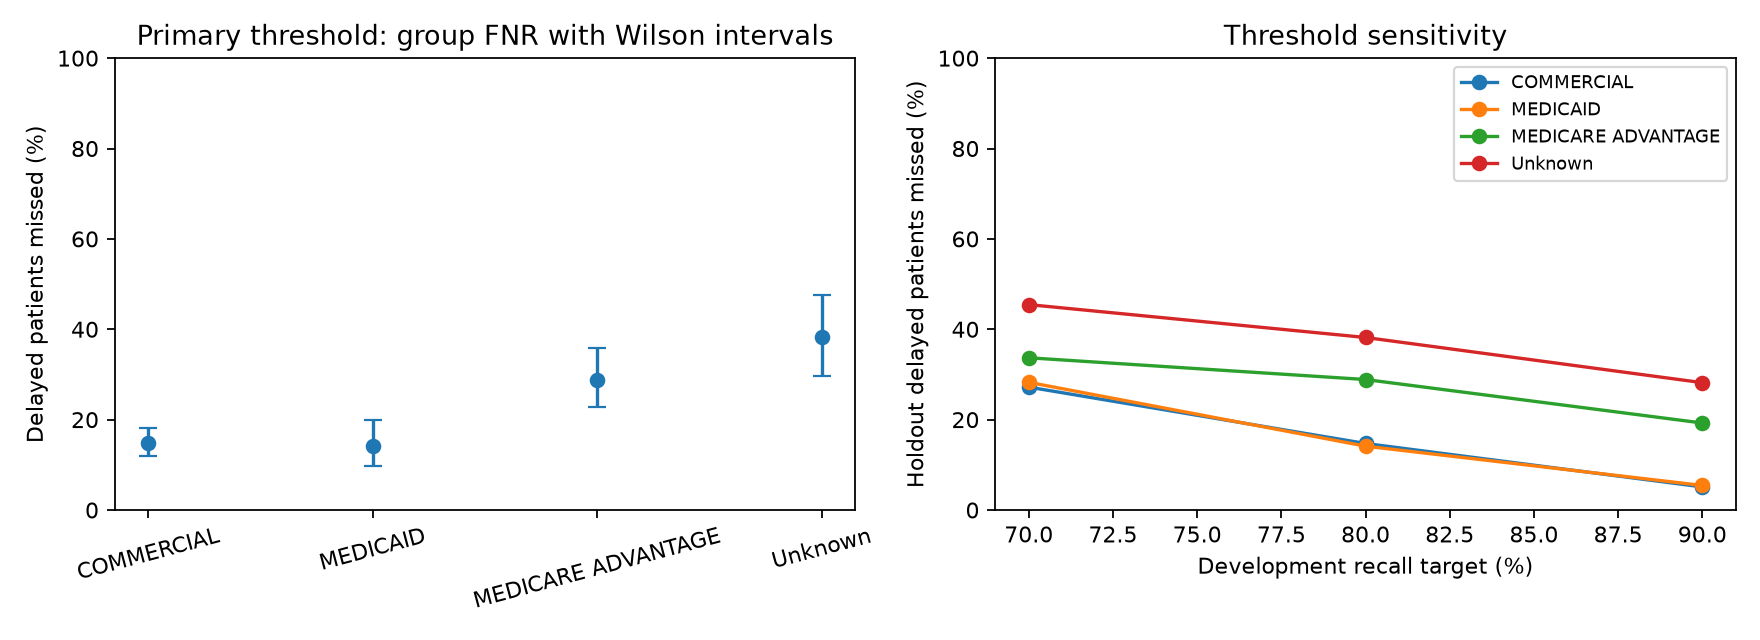

In [2]:
primary = run_insurance_audit(dev, hold)
display(pd.read_csv(ROOT / "reports/tables/insurance_audit_thresholds.csv"))
display(primary[["insurance", "patients", "delayed", "false_negative", "fnr", "fnr_low", "fnr_high", "fpr", "auc"]])
display(Image(filename=str(ROOT / "reports/images/insurance_audit.png")))

## Check alternative explanations and uncertainty

Resample ZIP-prefix clusters for group-minus-COMMERCIAL FNR differences. Check coding-family strata using the same threshold. These are exploratory checks, not causal adjustment; coding strings do not establish measurement dates or clinical cohorts.

In [3]:
display(pd.read_csv(ROOT / "reports/tables/insurance_audit_fnr_gaps.csv"))
strata = pd.read_csv(ROOT / "reports/tables/insurance_audit_coding_strata.csv")
display(strata[["coding_family", "insurance", "patients", "delayed", "false_negative", "fnr", "small_delayed_count"]])

,insurance,reference,fnr_difference,low,high,valid_replicates,zip_clusters
0,COMMERCIAL,COMMERCIAL,0.000000,0.000000,0.000000,1000,566
1,MEDICAID,COMMERCIAL,-0.005935,-0.059536,0.053618,1000,566
2,MEDICARE ADVANTAGE,COMMERCIAL,0.141531,0.067694,0.220027,1000,566
3,Unknown,COMMERCIAL,0.234579,0.135633,0.334439,1000,566


,coding_family,insurance,patients,delayed,false_negative,fnr,small_delayed_count
0,C-prefixed,COMMERCIAL,911,211,72,0.341232,False
1,C-prefixed,MEDICAID,401,89,26,0.292135,False
2,C-prefixed,MEDICARE ADVANTAGE,382,79,54,0.683544,False
3,C-prefixed,Unknown,293,57,42,0.736842,False
4,Numeric-only,COMMERCIAL,303,278,0,0.000000,False
5,Numeric-only,MEDICAID,106,95,0,0.000000,False
6,Numeric-only,MEDICARE ADVANTAGE,124,108,0,0.000000,False
7,Numeric-only,Unknown,62,53,0,0.000000,False


## Try one change and recheck

Estimate one threshold per insurance group from development OOF delayed cases, targeting the same 80% recall. Groups with fewer than 30 development delayed cases use the global fallback. Do not tune these thresholds against the holdout.

Keep this candidate only for further research if it shrinks the group FNR gap, does not increase the worst group FNR, and does not increase overall FPR. These are relative research checks, not clinical acceptance standards. Review the group FPRs as well as averages.

         policy      fnr      fpr  fnr_gap  worst_group_fnr
global_baseline 0.200000 0.447270 0.240514         0.381818
group_candidate 0.204124 0.460918 0.082353         0.245989


                    check  baseline  candidate  passed
    Smaller group FNR gap  0.240514   0.082353    True
No higher worst-group FNR  0.381818   0.245989    True
    No higher overall FPR  0.447270   0.460918   False


{
  "research_comparison": "do_not_adopt_under_current_guardrails",
  "all_relative_checks_passed": false,
  "default_policy": "global_baseline",
  "failed_relative_checks": [
    "No higher overall FPR"
  ],
  "reason": "Failed relative research checks: No higher overall FPR",
  "production_acceptance": "not_established"
}


,policy,false_negative,false_positive,fnr,fpr,fnr_gap,worst_group_fnr
0,global_baseline,194,721,0.200000,0.447270,0.240514,0.381818
1,group_candidate,198,743,0.204124,0.460918,0.082353,0.245989


,policy,insurance,delayed,false_negative,fnr,fpr
0,global_baseline,COMMERCIAL,489,72,0.147239,0.555862
1,global_baseline,MEDICAID,184,26,0.141304,0.637771
2,global_baseline,MEDICARE ADVANTAGE,187,54,0.288770,0.200627
3,global_baseline,Unknown,110,42,0.381818,0.195918
4,group_candidate,COMMERCIAL,489,100,0.204499,0.453793
5,group_candidate,MEDICAID,184,34,0.184783,0.547988
6,group_candidate,MEDICARE ADVANTAGE,187,46,0.245989,0.322884
7,group_candidate,Unknown,110,18,0.163636,0.546939


,check,baseline,candidate,passed
0,Smaller group FNR gap,0.240514,0.082353,True
1,No higher worst-group FNR,0.381818,0.245989,True
2,No higher overall FPR,0.447270,0.460918,False


,metric,candidate_minus_baseline,low,high
0,fnr_gap,-0.158161,-0.274568,-0.017526
1,worst_group_fnr,-0.135829,-0.234236,-0.038877
2,fpr,0.013648,-0.008404,0.034727


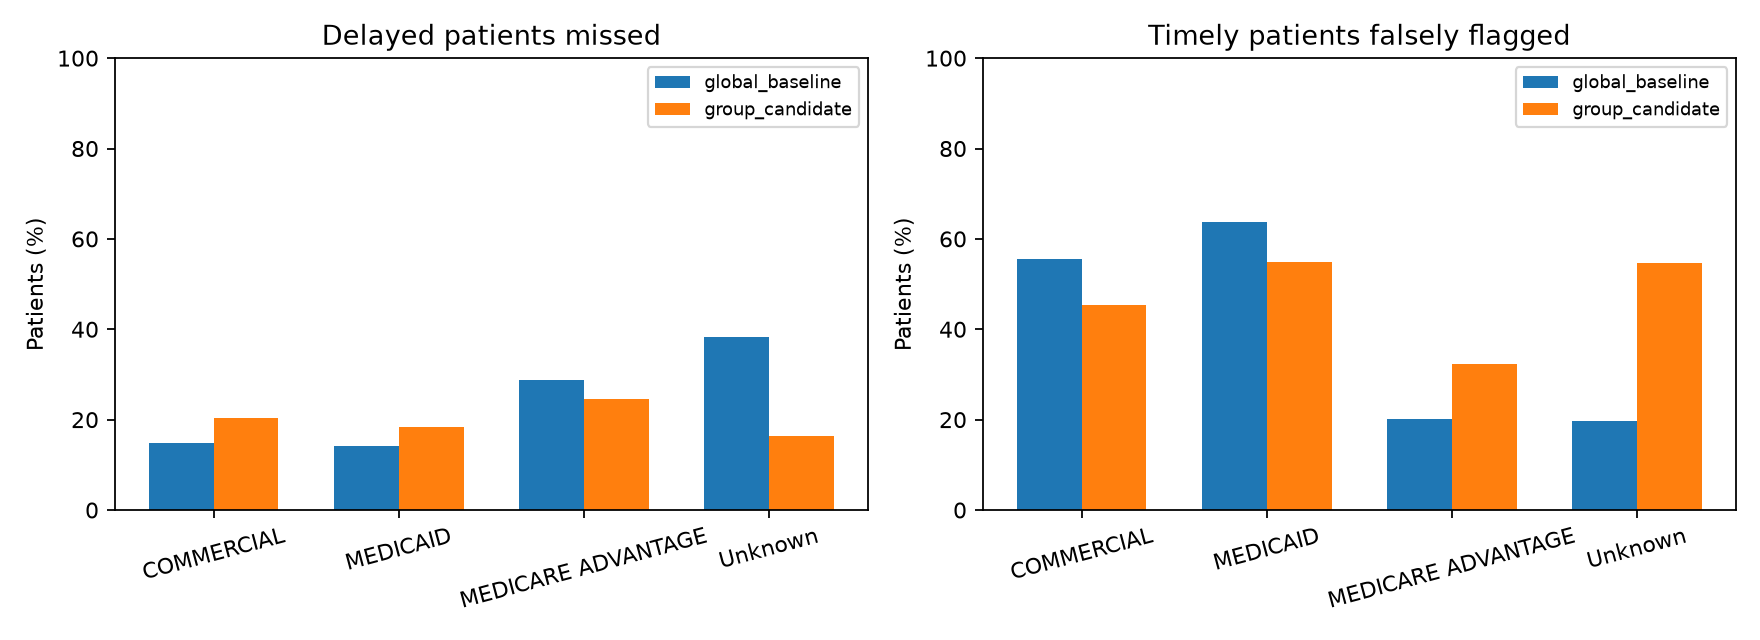

In [4]:
overall, groups, checks, decision = review_threshold_candidate(dev, hold)
display(overall[["policy", "false_negative", "false_positive", "fnr", "fpr", "fnr_gap", "worst_group_fnr"]])
display(groups[["policy", "insurance", "delayed", "false_negative", "fnr", "fpr"]])
display(checks)
display(pd.read_csv(ROOT / "reports/tables/insurance_review_changes.csv"))
display(Image(filename=str(ROOT / "reports/images/insurance_review.png")))

## Record the decision

Smaller group disparities need not mean fewer errors overall. Keep the original probabilities and competition submission unchanged. A rejected candidate still completes the research review. The outcome below is not permission for clinical use; feature timestamps and independent external validation are missing.

In [5]:
print("Research decision:", decision["research_comparison"])
print("Reason:", decision["reason"])
print("Retained baseline:", decision["default_policy"])
print("Clinical acceptance:", decision["production_acceptance"])

Research decision: do_not_adopt_under_current_guardrails
Reason: Failed relative research checks: No higher overall FPR
Retained baseline: global_baseline
Clinical acceptance: not_established
